# Data Acquisation and Cleaning

In [1]:
import pandas as pd
import torch 
import seaborn as sns 
import matplotlib.pyplot as plt 

from transformers import pipeline

In [2]:
df = pd.read_csv('reviews.csv')

In [3]:
df.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,2539,55688172,2015-12-04,25160947,Peter,Great host
1,2539,97474898,2016-08-27,91513326,Liz,Nice room for the price. Great neighborhood. J...
2,2539,105340344,2016-10-01,90022459,Евгений,Very nice apt. New remodeled.
3,2539,133131670,2017-02-20,116165195,George,Great place to stay for a while. John is a gre...
4,2539,138349776,2017-03-19,118432644,Carlos,.


In [4]:
df.columns

Index(['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments'], dtype='object')

In [5]:
print('Missing Values: ')
df.isna().sum()

Missing Values: 


listing_id         0
id                 0
date               0
reviewer_id        0
reviewer_name      3
comments         276
dtype: int64

In [6]:
df = df.dropna().copy()
df.isna().sum()

listing_id       0
id               0
date             0
reviewer_id      0
reviewer_name    0
comments         0
dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 998820 entries, 0 to 999098
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   listing_id     998820 non-null  int64 
 1   id             998820 non-null  int64 
 2   date           998820 non-null  object
 3   reviewer_id    998820 non-null  int64 
 4   reviewer_name  998820 non-null  object
 5   comments       998820 non-null  object
dtypes: int64(3), object(3)
memory usage: 53.3+ MB


In [8]:
max_words = df['comments'].str.split().str.len().describe([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95,0.99])
max_words
# so we gonna do the summarization so we are going to get the comments with large nuumber of words 
# we gonnna get according to that 

count    998820.00000
mean         43.93720
std          44.52723
min           1.00000
10%           6.00000
20%          11.00000
30%          17.00000
40%          24.00000
50%          31.00000
60%          40.00000
70%          52.00000
80%          68.00000
90%          97.00000
95%         131.00000
99%         192.00000
max        1000.00000
Name: comments, dtype: float64

In [9]:
df["word_count"] = df["comments"].str.split().str.len()

high_word_df = df[df["word_count"] > 192]

sample_df = high_word_df.sample(
    n=200,
    random_state=42
)

In [10]:
sample_df['word_count'].describe()

count    200.000000
mean     275.890000
std       99.649929
min      193.000000
25%      212.750000
50%      239.000000
75%      301.000000
max      787.000000
Name: word_count, dtype: float64

In [11]:
df = sample_df.copy()

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ",device)
print(torch.cuda.get_device_name(0))

Device:  cuda
NVIDIA GeForce GTX 1650


# Loading Model & Sentiment Analysis

In [13]:
model_name = "textattack/bert-base-uncased-SST-2"

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model= model_name,
    device= device
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [14]:
# testing on few comments

sample_comments = df['comments'].head().tolist()
results = sentiment_pipeline(sample_comments)
results

[{'label': 'LABEL_1', 'score': 0.9039698839187622},
 {'label': 'LABEL_1', 'score': 0.9994534850120544},
 {'label': 'LABEL_1', 'score': 0.9838712215423584},
 {'label': 'LABEL_1', 'score': 0.9976418018341064},
 {'label': 'LABEL_1', 'score': 0.7796650528907776}]

In [15]:
# lets apply over entire column 

comments = df['comments'].tolist()

results = sentiment_pipeline(
    comments,
    batch_size= 32,
    truncation= True
)

In [16]:
df['sentiment'] = ['Positive' if result['label']=='LABEL_1' else 'Negative'
                  for result in results]

df['sentiment_score'] = [result['score'] for result in results]

In [17]:
df.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments,word_count,sentiment,sentiment_score
280768,15706863,295935586,2018-07-24,183574363,Katja,We were a group of 5 young adults from Germany...,283,Positive,0.903970
385681,21852332,728425253,2021-02-01,195617611,Daniel,Had incredible weeklong stay. The apartment h...,257,Positive,0.999453
332275,19103622,330449029,2018-09-30,2961190,T.J.,"Aigerim and Alex are great hosts. Friendly, he...",299,Positive,0.983871
78323,1072481,58129379,2016-01-01,45298235,Esther,It has been my first time in Airbnb. Michael w...,235,Positive,0.997642
292624,15927523,175339496,2017-07-28,52845299,Wodan,In general I liked our stay at Jennifers locat...,197,Positive,0.779665


In [18]:
df["sentiment"].value_counts()

sentiment
Positive    150
Negative     50
Name: count, dtype: int64

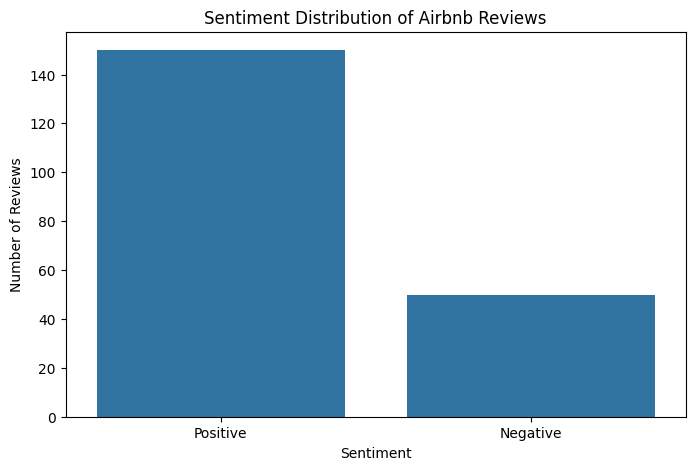

In [19]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='sentiment'
)

plt.title("Sentiment Distribution of Airbnb Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [20]:
sentiment_percentage = (
    df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(sentiment_percentage)

sentiment
Positive    75.0
Negative    25.0
Name: proportion, dtype: float64


In [21]:
print('Review: ',df['comments'].iloc[4])
print()
print('Sentiment Score: ',df['sentiment_score'].iloc[4])
print()
print('Sentiment: ',df['sentiment'].iloc[4])

Review:  In general I liked our stay at Jennifers location. We have not seen her in person but she was available via text/cellphone and was friendly (even in allowing us to stay until the evening on checkout date as we had a late night flight). The appt is more or less as at the pics. However still the pics show the place a bit more spacious compared to reality (guess some small wideangle on the camera was used in combination with increasing brightness). Also there was only 1 seat/couch instead of the 2 couches on the pictures. Access to the appt was easy even while we saw nobody. Just take into account a 10-15min walk to Bedford Av subway. Jennifer had some info ready to show us the nearby shops and restaurants which was also appreciated. The courtyard can be used (after approval from Jennifer) but the furniture needs to be taken from inside which is rather heavy/difficult to move. There were also no drapes to cover the window in the livingroom so make sure to have eyepads when you ne

# Loading Model & Review Summarization

In [22]:
from transformers import(
     AutoTokenizer,
     AutoModelForSeq2SeqLM
)

In [23]:
model_name = "sshleifer/distilbart-cnn-12-6"

tokenizer = AutoTokenizer.from_pretrained(model_name)

In [24]:
text = df["comments"].iloc[25]

tokens = tokenizer.tokenize(text)

print(tokens)

['The', 'ĠWr', 'ights', 'âĢ', 'Ļ', 'Ġplace', 'Ġis', 'Ġa', 'Ġreally', 'Ġgood', 'Ġfind', 'Ġif', 'Ġyou', 'âĢ', 'Ļ', 're', 'Ġlooking', 'Ġto', 'Ġstay', 'Ġin', 'ĠBrooklyn', 'Ġand', 'Ġyou', 'Ġneed', 'Ġto', 'Ġhave', 'Ġa', 'Ġcomfortable', ',', 'Ġquiet', 'Ġspace', 'Ġthat', 'Ġis', 'Ġnot', 'Ġexpensive', '.', 'ĠEverything', 'Ġwas', 'Ġas', 'Ġlisted', 'Ġon', 'ĠAirbnb', 'Ġand', 'Ġthe', 'Ġbathrooms', 'Ġwere', 'Ġcleaned', 'Ġevery', 'Ġday', '.', 'ĠWe', 'Ġwere', 'Ġlucky', 'Ġto', 'Ġfind', 'Ġthis', 'Ġroom', 'Ġavailable', 'Ġbecause', 'Ġit', 'Ġspared', 'Ġus', 'Ġa', 'Ġlot', 'Ġof', 'Ġmoney', '.', 'ĠIt', 'Ġis', 'Ġalso', 'Ġa', 'Ġ2', 'Ġminute', 'Ġwalk', 'Ġfrom', 'Ġthe', 'ĠG', 'Ġtrain', 'Ġsubway', 'Ġstation', 'Ġand', 'Ġit', 'Ġis', 'Ġabout', 'Ġa', 'Ġ30', 'Ġminute', 'Ġtrain', 'Ġride', 'Ġto', 'ĠManhattan', '.', 'ĠThere', 'âĢ', 'Ļ', 's', 'Ġcoffee', 'Ġplaces', 'Ġaround', 'Ġand', 'Ġplaces', 'Ġto', 'Ġget', 'Ġbreakfast', '.', 'Ġ<', 'br', '/>', 'The', 'Ġone', 'Ġinconvenience', 'Ġwas', 'Ġthe', 'ĠAC', 'Ġwhich', 'Ġcould', 'Ġno

In [25]:
input_ids = tokenizer(text)["input_ids"]

print(input_ids[:20])

[0, 133, 23511, 6183, 17, 27, 317, 16, 10, 269, 205, 465, 114, 47, 17, 27, 241, 546, 7, 1095]


In [26]:
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

model = model.to(device)

model.eval()

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

BartForConditionalGeneration(
  (model): BartModel(
    (shared): BartScaledWordEmbedding(50264, 1024, padding_idx=1)
    (encoder): BartEncoder(
      (embed_tokens): BartScaledWordEmbedding(50264, 1024, padding_idx=1)
      (embed_positions): BartLearnedPositionalEmbedding(1026, 1024)
      (layers): ModuleList(
        (0-11): 12 x BartEncoderLayer(
          (self_attn): BartAttention(
            (k_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (v_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (q_proj): Linear(in_features=1024, out_features=1024, bias=True)
            (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (self_attn_layer_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
          (activation_fn): GELUActivation()
          (fc1): Linear(in_features=1024, out_features=4096, bias=True)
          (fc2): Linear(in_features=4096, out_features=1024, bias=True)
        

In [27]:
# test ONE review first

review = df['comments'].iloc[25]
print(review)

The Wrights’ place is a really good find if you’re looking to stay in Brooklyn and you need to have a comfortable, quiet space that is not expensive. Everything was as listed on Airbnb and the bathrooms were cleaned every day. We were lucky to find this room available because it spared us a lot of money. It is also a 2 minute walk from the G train subway station and it is about a 30 minute train ride to Manhattan. There’s coffee places around and places to get breakfast. <br/>The one inconvenience was the AC which could not be turned off in the room. I talked to one of the hosts and he was really nice to turn it down so that it wouldn’t get as cold in the room, but even so it would start at random times in the night and the vent made a noise that woke us up a couple times. If they fix that in the future this Airbnb stay would be one of the best in Brooklyn for the value of money! <br/>Overall, I recommend this to everyone, but be careful if you are sensitive to AC.


In [28]:
inputs = tokenizer(
    review,
    return_tensors="pt",
    truncation=True,
    max_length=1024
)

In [29]:
inputs.keys()

KeysView({'input_ids': tensor([[    0,   133, 23511,  6183,    17,    27,   317,    16,    10,   269,
           205,   465,   114,    47,    17,    27,   241,   546,     7,  1095,
            11,  6314,     8,    47,   240,     7,    33,    10,  3473,     6,
          5128,   980,    14,    16,    45,  3214,     4,  9567,    21,    25,
          3147,    15, 16315,     8,     5, 18409,    58, 17317,   358,   183,
             4,   166,    58,  5394,     7,   465,    42,   929,   577,   142,
            24, 20634,   201,    10,   319,     9,   418,     4,    85,    16,
            67,    10,   132,  2289,  1656,    31,     5,   272,  2341, 15604,
          1992,     8,    24,    16,    59,    10,   389,  2289,  2341,  3068,
             7,  6562,     4,   345,    17,    27,    29,  3895,  2127,   198,
             8,  2127,     7,   120,  7080,     4, 28696,  3809, 49666,   133,
            65, 24109,    21,     5,  7224,    61,   115,    45,    28,  1224,
           160,    11,     5,

In [30]:
# moving tensors  to GPU
inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

In [31]:
with torch.no_grad():
    summary_ids = model.generate(
        **inputs,
        max_length=80,
        min_length=50,
        num_beams=4,
        no_repeat_ngram_size=3
    )

In [32]:
summary = tokenizer.decode(
    summary_ids[0],
    skip_special_tokens=True
)

print("Original:")
print(review)

print("\nSummary:")
print(summary)

Original:
The Wrights’ place is a really good find if you’re looking to stay in Brooklyn and you need to have a comfortable, quiet space that is not expensive. Everything was as listed on Airbnb and the bathrooms were cleaned every day. We were lucky to find this room available because it spared us a lot of money. It is also a 2 minute walk from the G train subway station and it is about a 30 minute train ride to Manhattan. There’s coffee places around and places to get breakfast. <br/>The one inconvenience was the AC which could not be turned off in the room. I talked to one of the hosts and he was really nice to turn it down so that it wouldn’t get as cold in the room, but even so it would start at random times in the night and the vent made a noise that woke us up a couple times. If they fix that in the future this Airbnb stay would be one of the best in Brooklyn for the value of money! <br/>Overall, I recommend this to everyone, but be careful if you are sensitive to AC.

Summary:


In [33]:
def summarize_text(text):

    inputs = tokenizer(
        text,
        return_tensors ='pt',
        max_length = 1024,
        truncation = True
    )

    inputs = {
        key:value.to(device)
        for key,value in inputs.items()
    }
    
    with torch.no_grad():
        summary = model.generate(
            **inputs,
            min_length = 80,
            max_length = 100,
            num_beams = 4,
            no_repeat_ngram_size = 3
        )

    summary = tokenizer.decode(
        summary[0],
        skip_special_tokens= True
    )

    return summary

In [34]:
print("Review: ")
print(df["comments"].iloc[1])
print()

summarized = summarize_text(df["comments"].iloc[1])
print("Summary: ")
print(summarized)

Review: 
Had incredible weeklong stay.  The apartment has a real nice layout with a front entry living room on one floor with the rest of the house on another floor.  The separation of the living room was an unexpected treat to give some additional quiet and privacy while reading or working.  The kitchen and dining room are spacious, has all the things necessary to cook and family of 4-6 to eat.<br/>The local area is safe and enjoyable.  Plenty of small store fronts to pick up quick breakfast or lunch, drinks, etc.  Broadway is a quick Lyft or drive away to pick up groceries.  The A train is just a couple blocks away to get to the rest of the city (although we didn’t train during our stay due to COVID).  Although is was exceptionally cold during our stay, favorite activity was to walk early in the morning either North or South to get coffee and experience the city.  <br/>Agnes and her husband as host were extremely considerate.  Due to our travel arrangements we needed to arrive earlie

In [35]:
# Create a batched summarization function
# using .apply will do one at a time 
# so we gonna use the GPU 

from transformers.utils import logging

logging.set_verbosity_error()

from tqdm.notebook import tqdm

def summarize_batch(texts, batch_size=8):
    all_summaries = []

    progress = tqdm(
        total=len(texts),
        desc="Summarizing reviews",
        unit="review"
    )

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        inputs = tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=1024
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        with torch.no_grad():
            summary_ids = model.generate(
                **inputs,
                min_new_tokens=20,
                max_new_tokens=80,
                num_beams=4,
                no_repeat_ngram_size=3
            )

        summaries = tokenizer.batch_decode(
            summary_ids,
            skip_special_tokens=True
        )

        all_summaries.extend(summaries)

        progress.update(len(batch))

    progress.close()

    return all_summaries

In [36]:
reviews = df["comments"].tolist()

print("Number of reviews:", len(reviews))

Number of reviews: 200


In [37]:
summaries = summarize_batch(
    reviews,
    batch_size=8
)

Summarizing reviews:   0%|          | 0/200 [00:00<?, ?review/s]

In [40]:
df["summary"] = summaries

In [41]:
for i in [0, 10, 50, 100, 190]:

    print("=" * 100)

    print("\nORIGINAL:")
    print(df["comments"].iloc[i])

    print("\nSentiment: ")
    print(df['sentiment'].iloc[i])
    
    print("\nSUMMARY:")
    print(df["summary"].iloc[i])


ORIGINAL:
We were a group of 5 young adults from Germany and we totally agree that Gretchen was a very kind and caring host. She always answered fast and friendly and wanted us to have a great time in New York. The apartment is located in a normal housing area of brooklyn, so no loud and busy streets with lots of tourists which was really nice. On the other hand, people who want to visit hyped restaurants will probably will have to plan it and have to know that they will have to reach them not that fast. But we mostly cooked at the apartment which leads to the tiny critic and the reason why i didn't choose the whole 5 stars: when you plan to cook a lot you will miss supplies like cutting boards or big bowls where you can eat soup from. We had to buy stuff like salt sugar and oil, but these things also may not be available because of hygiene. Also bring a lighter as the one that was in the kitchen didn't work well. So that was the things we've missed a little but now the reasons why i'

# WordCloud

In [42]:
all_summaries = " ".join(
    df["summary"].dropna()
)

In [43]:
import re

text = all_summaries.lower()

# Remove HTML
text = re.sub(r"<.*?>", " ", text)

# Keep only words
words = re.findall(r"\b[a-z]+\b", text)

In [44]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

words = [
    word for word in words
    if word not in stop_words
]

In [48]:
clean_text = " ".join(words)

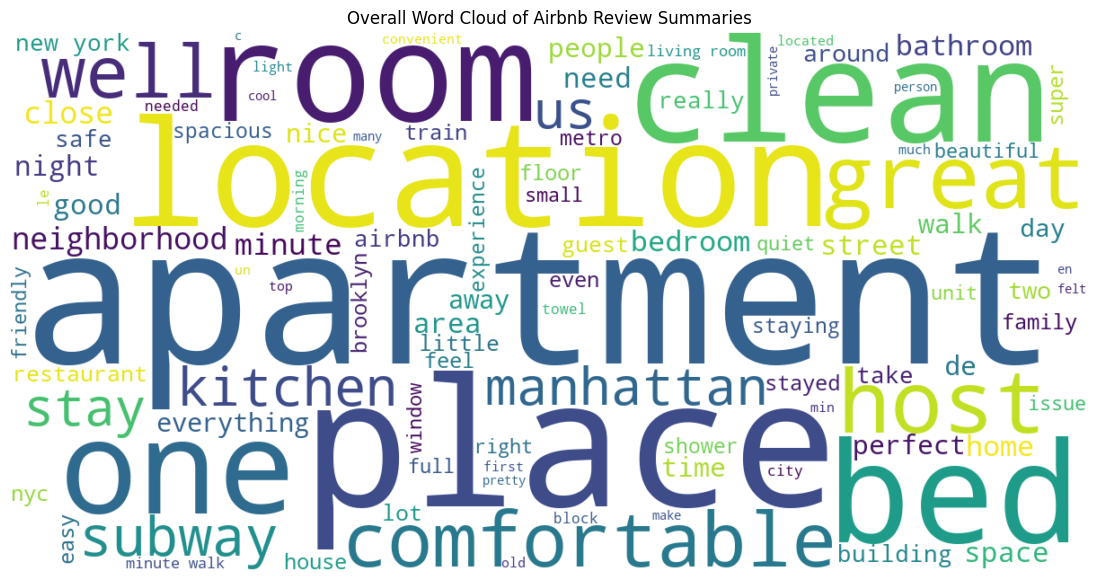

In [49]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(clean_text)

plt.figure(figsize=(15, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")
plt.title("Overall Word Cloud of Airbnb Review Summaries")

plt.show()